In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb

## Data Integration


In [2]:
dataframe = pd.read_table("https://archive.ics.uci.edu/ml/machine-learning-databases/echocardiogram/echocardiogram.data")
dataframe.to_csv('echocardiogram.csv', index = None)

data = pd.read_csv('/content/echocardiogram.csv', sep=",", header=None)
data

,0
0,"11,0,71,0,0.260,9,4.600,14,1,1,name,1,0"
1,"19,0,72,0,0.380,6,4.100,14,1.700,0.588,name,1,0"
2,"16,0,55,0,0.260,4,3.420,14,1,1,name,1,0"
3,"57,0,60,0,0.253,12.062,4.603,16,1.450,0.788,na..."
4,"19,1,57,0,0.160,22,5.750,18,2.250,0.571,name,1,0"
...,...
127,"7.5,1,64,0,0.24,12.9,4.72,12,1,0.857,name,?,?"
128,"41,0,64,0,0.28,5.40,5.47,11,1.10,0.714,name,?,?"
129,"36,0,69,0,0.20,7.00,5.05,14.5,1.21,0.857,name,?,?"
130,"22,0,57,0,0.14,16.1,4.36,15,1.36,0.786,name,?,?"


In [3]:
data.columns = ["col"]
data = data['col'].str.split(',', expand=True)
data

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,11,0,71,0,0.260,9,4.600,14,1,1,name,1,0,None
1,19,0,72,0,0.380,6,4.100,14,1.700,0.588,name,1,0,None
2,16,0,55,0,0.260,4,3.420,14,1,1,name,1,0,None
3,57,0,60,0,0.253,12.062,4.603,16,1.450,0.788,name,1,0,None
4,19,1,57,0,0.160,22,5.750,18,2.250,0.571,name,1,0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,7.5,1,64,0,0.24,12.9,4.72,12,1,0.857,name,?,?,None
128,41,0,64,0,0.28,5.40,5.47,11,1.10,0.714,name,?,?,None
129,36,0,69,0,0.20,7.00,5.05,14.5,1.21,0.857,name,?,?,None
130,22,0,57,0,0.14,16.1,4.36,15,1.36,0.786,name,?,?,None


In [4]:
data = data.drop([13], axis=1)

In [5]:
data.columns = ['Survival','StillAlive','AgeAtHeartAttack','PericardialEffusion','FractionalShortening','Epss','Lvdd','WallMotionScore','WallMotionIndex','Mult','Name','Group','AliveAt1']
data = data.replace({'?': np.nan})

data = data.dropna(subset=['StillAlive']).copy()
data = data.drop(['Name', 'Group', 'AliveAt1'], axis=1)
data.head()

print(f"Final shape: {data.shape}")
data

Final shape: (131, 10)


,Survival,StillAlive,AgeAtHeartAttack,PericardialEffusion,FractionalShortening,Epss,Lvdd,WallMotionScore,WallMotionIndex,Mult
0,11,0,71,0,0.260,9,4.600,14,1,1
1,19,0,72,0,0.380,6,4.100,14,1.700,0.588
2,16,0,55,0,0.260,4,3.420,14,1,1
3,57,0,60,0,0.253,12.062,4.603,16,1.450,0.788
4,19,1,57,0,0.160,22,5.750,18,2.250,0.571
...,...,...,...,...,...,...,...,...,...,...
127,7.5,1,64,0,0.24,12.9,4.72,12,1,0.857
128,41,0,64,0,0.28,5.40,5.47,11,1.10,0.714
129,36,0,69,0,0.20,7.00,5.05,14.5,1.21,0.857
130,22,0,57,0,0.14,16.1,4.36,15,1.36,0.786


## Model Training and Evaluation

In [6]:
X_final = data.drop(columns=['StillAlive', 'Survival'], errors='ignore')
y_final = data['StillAlive']

In [7]:
discrete_cols = ['PericardialEffusion']
num_cols = [col for col in X_final.columns if col not in discrete_cols]

In [16]:
preprocessor_final = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols)
], remainder='passthrough')

In [19]:
cv_final = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

In [25]:
y_final_numeric = y_final.astype(int)

xgb_pipeline = Pipeline([
    ('pre', preprocessor_final),
    ('clf', xgb.XGBClassifier(random_state=0))
])

param_distributions = {
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'clf__max_depth': [3, 4, 5, 6, 7],
    'clf__min_child_weight': [1, 3, 5],
    'clf__gamma': [0.0, 0.1, 0.2, 0.3, 0.4]
}

tuned_xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=cv_final,
    scoring='accuracy',
    n_jobs=-1,
    random_state=0
)
tuned_xgb_search.fit(X_final, y_final_numeric)

best_xgb_model = tuned_xgb_search.best_estimator_['clf']
print("Best XGBoost Hyperparameters:", tuned_xgb_search.best_params_)

Best XGBoost Hyperparameters: {'clf__min_child_weight': 5, 'clf__max_depth': 6, 'clf__learning_rate': 0.3, 'clf__gamma': 0.3}


In [34]:
models_final = {
    'Baseline (Most Frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced', random_state=0),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=0),
    'Random Forest': RandomForestClassifier(max_depth=4, class_weight='balanced', random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=0),
    'Tuned XGBoost': best_xgb_model
}

final_results = []

for name, model in models_final.items():
    pipeline_eval = Pipeline([
        ('pre', preprocessor_final),
        ('clf', model)
    ])

    scores = cross_validate(pipeline_eval, X_final, y_final_numeric, cv=cv_final, scoring=['accuracy', 'f1', 'roc_auc'], n_jobs=-1)

    final_results.append({
        'Model': name,
        'Accuracy (%)': round(scores['test_accuracy'].mean() * 100, 2),
        'F1-Score (%)': round(scores['test_f1'].mean() * 100, 2),
        'ROC-AUC (%)': round(scores['test_roc_auc'].mean() * 100, 2)
    })

df_final_performance = pd.DataFrame(final_results)
display(df_final_performance)

,Model,Accuracy (%),F1-Score (%),ROC-AUC (%)
0,Baseline (Most Frequent),67.18,0.00,50.00
1,Logistic Regression,72.07,59.66,76.56
2,Decision Tree,61.07,50.82,62.48
3,Random Forest,70.09,53.51,74.65
4,Gradient Boosting,65.65,43.68,66.46
5,Tuned XGBoost,69.19,46.19,72.31


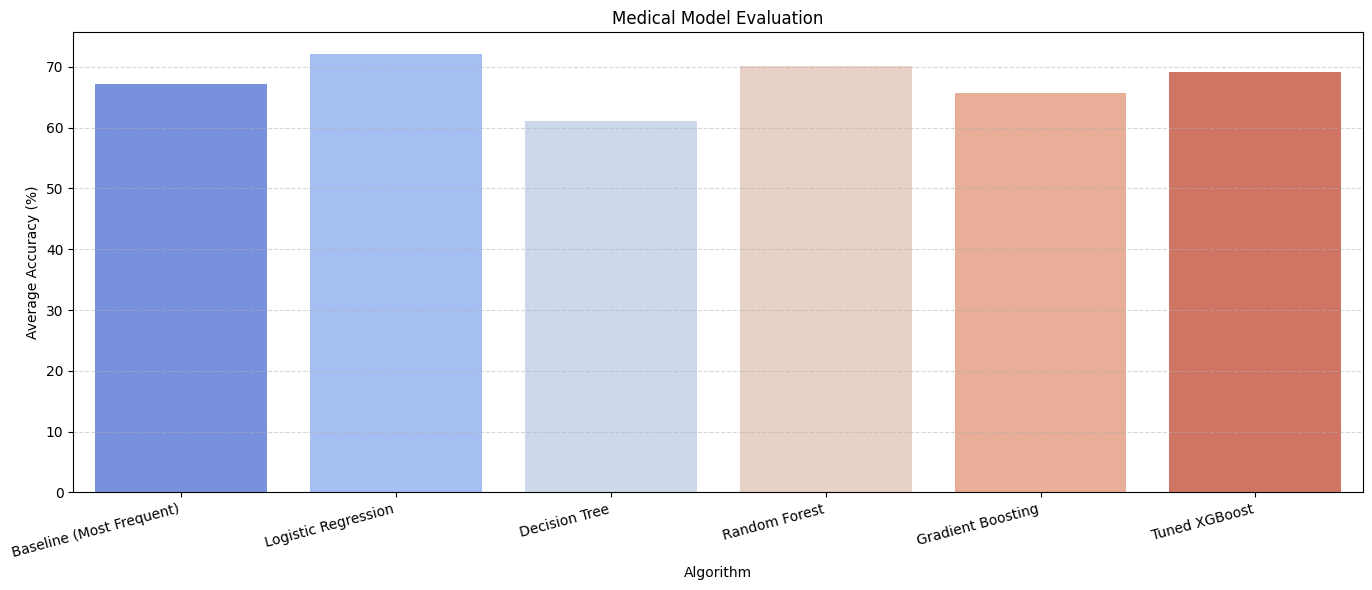

In [37]:
plt.figure(figsize=(14, 6))
sns.barplot(x='Model', y='Accuracy (%)', data=df_final_performance, hue='Model', palette='coolwarm', legend=False)
plt.title('Medical Model Evaluation')
plt.ylabel('Average Accuracy (%)')
plt.xlabel('Algorithm')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()